In [1]:
import pandas as pd

In [2]:
df_mut = pd.read_csv('../data/mutaciones/mut_gen_cancer_type_STKR.csv')
df_mut

,tipo_cancer,Gen_names,mutation_count
0,Cabeza,ACVR1,5
1,Cabeza,ACVR1B,19
2,Cabeza,ACVR1C,27
3,Cabeza,ACVR2A,5
4,Cabeza,ACVR2B,3
...,...,...,...
184,Vesicula,AMHR2,1
185,Vesicula,BMPR1B,6
186,Vesicula,BMPR2,1
187,Vesicula,TGFBR1,14


In [3]:
df_xena_exp = pd.read_csv('../data/Xena API/clineexp_long_STKR.csv')
df_xena_exp

,_primary_site,_sample_type,Gene,Normalized Expression
0,Uterus,Primary Tumor,BMPR1B,0.536299
1,Uterus,Primary Tumor,BMPR1B,0.516657
2,Uterus,Primary Tumor,BMPR1B,0.585791
3,Uterus,Primary Tumor,BMPR1B,0.452537
4,Uterus,Primary Tumor,BMPR1B,0.567761
...,...,...,...,...
145687,Heart,Normal Tissue,ACVR1C,0.404173
145688,Heart,Normal Tissue,ACVR1C,0.431866
145689,Heart,Normal Tissue,ACVR1C,0.496965
145690,Heart,Normal Tissue,ACVR1C,0.424734


In [4]:
exp_tumor = df_xena_exp.loc[(df_xena_exp['_sample_type']=='Primary Tumor')] 

In [5]:
exp_tumor

,_primary_site,_sample_type,Gene,Normalized Expression
0,Uterus,Primary Tumor,BMPR1B,0.536299
1,Uterus,Primary Tumor,BMPR1B,0.516657
2,Uterus,Primary Tumor,BMPR1B,0.585791
3,Uterus,Primary Tumor,BMPR1B,0.452537
4,Uterus,Primary Tumor,BMPR1B,0.567761
...,...,...,...,...
141431,Bladder,Primary Tumor,ACVR1C,0.561988
141432,Bladder,Primary Tumor,ACVR1C,0.128225
141433,Bladder,Primary Tumor,ACVR1C,0.194613
141434,Bladder,Primary Tumor,ACVR1C,0.064537


In [6]:
exp_tumor_mean = exp_tumor.groupby(['Gene','_primary_site', '_sample_type'])['Normalized Expression'].agg(['mean', 'std']).reset_index()
exp_tumor_mean

,Gene,_primary_site,_sample_type,mean,std
0,ACVR1,Bladder,Primary Tumor,0.596704,0.045993
1,ACVR1,Brain,Primary Tumor,0.615109,0.027460
2,ACVR1,Breast,Primary Tumor,0.640083,0.036883
3,ACVR1,Cervix,Primary Tumor,0.613012,0.041667
4,ACVR1,Colon,Primary Tumor,0.599087,0.027364
...,...,...,...,...,...
199,TGFBR2,Prostate,Primary Tumor,0.663747,0.054874
200,TGFBR2,Skin,Primary Tumor,0.691733,0.064552
201,TGFBR2,Stomach,Primary Tumor,0.762451,0.056754
202,TGFBR2,Thyroid Gland,Primary Tumor,0.710930,0.044175


In [7]:


from deep_translator import GoogleTranslator
import pandas as pd


# Traducir la columna
df_mut['ColumnaTraducida'] = df_mut['tipo_cancer'].apply(lambda x: GoogleTranslator(source='auto', target='en').translate(x))

df_mut


,tipo_cancer,Gen_names,mutation_count,ColumnaTraducida
0,Cabeza,ACVR1,5,Head
1,Cabeza,ACVR1B,19,Head
2,Cabeza,ACVR1C,27,Head
3,Cabeza,ACVR2A,5,Head
4,Cabeza,ACVR2B,3,Head
...,...,...,...,...
184,Vesicula,AMHR2,1,Vesicle
185,Vesicula,BMPR1B,6,Vesicle
186,Vesicula,BMPR2,1,Vesicle
187,Vesicula,TGFBR1,14,Vesicle


In [8]:
df_mut.loc[df_mut['ColumnaTraducida']=='Head', 'ColumnaTraducida'] = 'Head and Neck region'
df_mut

,tipo_cancer,Gen_names,mutation_count,ColumnaTraducida
0,Cabeza,ACVR1,5,Head and Neck region
1,Cabeza,ACVR1B,19,Head and Neck region
2,Cabeza,ACVR1C,27,Head and Neck region
3,Cabeza,ACVR2A,5,Head and Neck region
4,Cabeza,ACVR2B,3,Head and Neck region
...,...,...,...,...
184,Vesicula,AMHR2,1,Vesicle
185,Vesicula,BMPR1B,6,Vesicle
186,Vesicula,BMPR2,1,Vesicle
187,Vesicula,TGFBR1,14,Vesicle


In [9]:
merge_corr = exp_tumor_mean.merge(df_mut, left_on=['Gene', '_primary_site'], right_on=['Gen_names', 'ColumnaTraducida'])
merge_corr.sort_values(by='mutation_count', ascending=False)

,Gene,_primary_site,_sample_type,mean,std,tipo_cancer,Gen_names,mutation_count,ColumnaTraducida
128,TGFBR1,Colon,Primary Tumor,0.696378,0.048731,Colon,TGFBR1,86,Colon
18,ACVR1B,Lung,Primary Tumor,0.699258,0.044569,Pulmon,ACVR1B,63,Lung
68,ACVRL1,Lung,Primary Tumor,0.664069,0.061776,Pulmon,ACVRL1,63,Lung
14,ACVR1B,Colon,Primary Tumor,0.718417,0.037400,Colon,ACVR1B,58,Colon
30,ACVR1C,Lung,Primary Tumor,0.479289,0.137111,Pulmon,ACVR1C,57,Lung
...,...,...,...,...,...,...,...,...,...
8,ACVR1,Pancreas,Primary Tumor,0.669126,0.031309,Pancreas,ACVR1,1,Pancreas
88,BMPR1A,Breast,Primary Tumor,0.780877,0.047779,Seno,BMPR1A,1,Breast
58,ACVR2B,Prostate,Primary Tumor,0.687841,0.046015,Prostata,ACVR2B,1,Prostate
2,ACVR1,Breast,Primary Tumor,0.640083,0.036883,Seno,ACVR1,1,Breast


In [10]:
merge_corr['_primary_site'].unique()


array(['Bladder', 'Brain', 'Breast', 'Colon', 'Head and Neck region',
       'Liver', 'Lung', 'Ovary', 'Pancreas', 'Stomach', 'Cervix',
       'Kidney', 'Prostate'], dtype=object)

In [11]:
merge_corr['tipo_cancer'].unique()

array(['Vejiga', 'Cerebro', 'Seno ', 'Colon', 'Cabeza', 'Higado',
       'Pulmon', 'Ovario', 'Pancreas', 'Estomago', 'Cervix', 'Riñon',
       'Prostata'], dtype=object)

In [12]:
merge_corr['ColumnaTraducida'].unique()

array(['Bladder', 'Brain', 'Breast', 'Colon', 'Head and Neck region',
       'Liver', 'Lung', 'Ovary', 'Pancreas', 'Stomach', 'Cervix',
       'Kidney', 'Prostate'], dtype=object)

In [13]:
import numpy as np

# Calcular el logaritmo base 10 de la columna 'mean'
merge_corr['log_mean'] = np.log10(merge_corr['mean'])
merge_corr['mutation_count_log'] = np.log10(merge_corr['mutation_count'])
merge_corr

,Gene,_primary_site,_sample_type,mean,std,tipo_cancer,Gen_names,mutation_count,ColumnaTraducida,log_mean,mutation_count_log
0,ACVR1,Bladder,Primary Tumor,0.596704,0.045993,Vejiga,ACVR1,7,Bladder,-0.224241,0.845098
1,ACVR1,Brain,Primary Tumor,0.615109,0.027460,Cerebro,ACVR1,6,Brain,-0.211048,0.778151
2,ACVR1,Breast,Primary Tumor,0.640083,0.036883,Seno,ACVR1,1,Breast,-0.193764,0.000000
3,ACVR1,Colon,Primary Tumor,0.599087,0.027364,Colon,ACVR1,8,Colon,-0.222510,0.903090
4,ACVR1,Head and Neck region,Primary Tumor,0.647353,0.045280,Cabeza,ACVR1,5,Head and Neck region,-0.188859,0.698970
...,...,...,...,...,...,...,...,...,...,...,...
144,TGFBR2,Lung,Primary Tumor,0.709731,0.066693,Pulmon,TGFBR2,24,Lung,-0.148906,1.380211
145,TGFBR2,Ovary,Primary Tumor,0.673095,0.060168,Ovario,TGFBR2,6,Ovary,-0.171923,0.778151
146,TGFBR2,Pancreas,Primary Tumor,0.775025,0.043359,Pancreas,TGFBR2,53,Pancreas,-0.110684,1.724276
147,TGFBR2,Prostate,Primary Tumor,0.663747,0.054874,Prostata,TGFBR2,2,Prostate,-0.177998,0.301030


In [14]:
import altair as alt

alt.Chart(merge_corr).transform_calculate(
).mark_point().encode(
    x='mutation_count',
    y='mean',
    #color=alt.Color('Gen_names', scale=alt.Scale(scheme='category20')),
    tooltip=['Gene']
)

alt.Chart(...)

In [15]:
import altair as alt


alt.Chart(merge_corr).transform_calculate(
).mark_point().encode(
    x='mutation_count_log',
    y='log_mean',
    color=alt.Color('Gen_names', scale=alt.Scale(scheme='category20')),
    tooltip=['Gene']
)

alt.Chart(...)

## Estadistica logaritmo

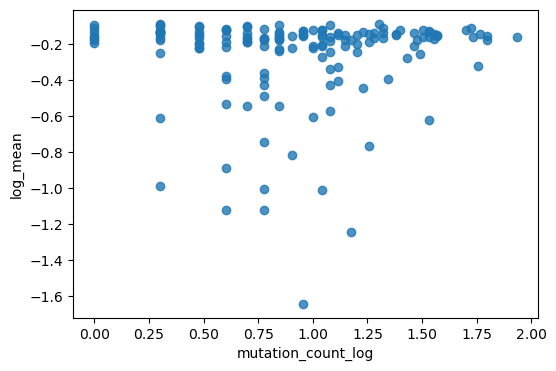

In [16]:
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns
# Gráfico
# ==============================================================================
fig, ax = plt.subplots(1, 1, figsize=(6,4))

# Especificar las columnas correctas para x y y
ax.scatter(x=merge_corr['mutation_count_log'], y=merge_corr['log_mean'], alpha=0.8)

ax.set_xlabel('mutation_count_log')
ax.set_ylabel('log_mean')
plt.show()


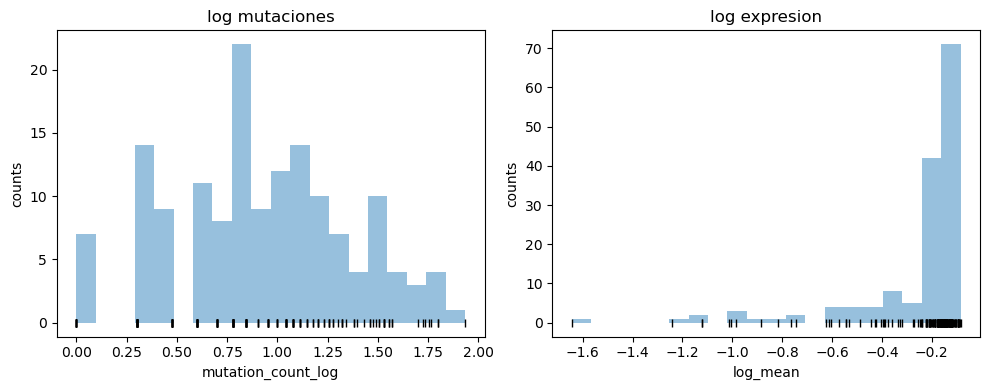

In [17]:
# Gráfico distribución variables
# ==============================================================================
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

axs[0].hist(x=merge_corr['mutation_count_log'], bins=20, color="#3182bd", alpha=0.5)
axs[0].plot(merge_corr['mutation_count_log'], np.full_like(merge_corr['mutation_count_log'], -0.01), '|k', markeredgewidth=1)
axs[0].set_title('log mutaciones')
axs[0].set_xlabel('mutation_count_log')
axs[0].set_ylabel('counts')

axs[1].hist(x=merge_corr['log_mean'], bins=20, color="#3182bd", alpha=0.5)
axs[1].plot(merge_corr['log_mean'], np.full_like(merge_corr['log_mean'], -0.01), '|k', markeredgewidth=1)
axs[1].set_title('log expresion')
axs[1].set_xlabel('log_mean')
axs[1].set_ylabel('counts')


plt.tight_layout();

In [18]:
import statsmodels.api as sm
import pingouin as pg
from scipy import stats
from scipy.stats import pearsonr

# Cálculo de correlación, significancia e intervalos con pingouin
# ==============================================================================
display(pg.corr(merge_corr['mutation_count_log'], merge_corr['log_mean'], method='pearson'))
display(pg.corr(merge_corr['mutation_count_log'], merge_corr['log_mean'], method='spearman'))
display(pg.corr(merge_corr['mutation_count_log'], merge_corr['log_mean'], method='kendall'))

,n,r,CI95%,p-val,BF10,power
pearson,149,0.030508,"[-0.13, 0.19]",0.71187,0.11,0.065697


,n,r,CI95%,p-val,power
spearman,149,-0.023739,"[-0.18, 0.14]",0.773829,0.059426


,n,r,CI95%,p-val,power
kendall,149,-0.00963,"[-0.17, 0.15]",0.86424,0.051454


## Estadistica normal

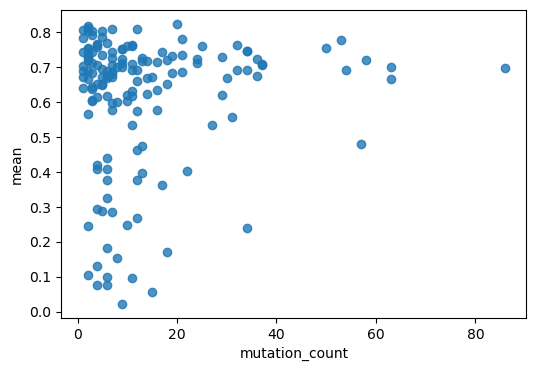

In [19]:
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns
# Gráfico
# ==============================================================================
fig, ax = plt.subplots(1, 1, figsize=(6,4))

# Especificar las columnas correctas para x y y
ax.scatter(x=merge_corr['mutation_count'], y=merge_corr['mean'], alpha=0.8)

ax.set_xlabel('mutation_count')
ax.set_ylabel('mean')
plt.show()


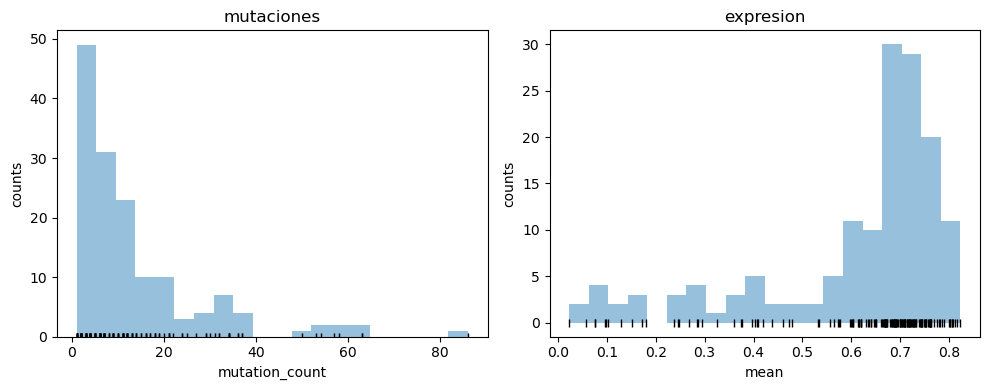

In [20]:
# Gráfico distribución variables
# ==============================================================================
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

axs[0].hist(x=merge_corr['mutation_count'], bins=20, color="#3182bd", alpha=0.5)
axs[0].plot(merge_corr['mutation_count'], np.full_like(merge_corr['mutation_count'], -0.01), '|k', markeredgewidth=1)
axs[0].set_title('mutaciones')
axs[0].set_xlabel('mutation_count')
axs[0].set_ylabel('counts')

axs[1].hist(x=merge_corr['mean'], bins=20, color="#3182bd", alpha=0.5)
axs[1].plot(merge_corr['mean'], np.full_like(merge_corr['mean'], -0.01), '|k', markeredgewidth=1)
axs[1].set_title('expresion')
axs[1].set_xlabel('mean')
axs[1].set_ylabel('counts')


plt.tight_layout();

In [21]:
import statsmodels.api as sm
import pingouin as pg
from scipy import stats
from scipy.stats import pearsonr

# Cálculo de correlación, significancia e intervalos con pingouin
# ==============================================================================
display(pg.corr(merge_corr['mutation_count'], merge_corr['mean'], method='pearson'))
display(pg.corr(merge_corr['mutation_count'], merge_corr['mean'], method='spearman'))
display(pg.corr(merge_corr['mutation_count'], merge_corr['mean'], method='kendall'))

,n,r,CI95%,p-val,BF10,power
pearson,149,0.109353,"[-0.05, 0.27]",0.184319,0.245,0.264914


,n,r,CI95%,p-val,power
spearman,149,-0.023739,"[-0.18, 0.14]",0.773829,0.059426


,n,r,CI95%,p-val,power
kendall,149,-0.00963,"[-0.17, 0.15]",0.86424,0.051454


# 2. Correlacion tumor/normal

In [22]:
exp_mean = df_xena_exp.groupby(['Gene', '_primary_site', '_sample_type'])['Normalized Expression'].agg(['mean', 'std']).reset_index()
exp_mean

,Gene,_primary_site,_sample_type,mean,std
0,ACVR1,Bladder,Normal Tissue,0.617858,0.014956
1,ACVR1,Bladder,Primary Tumor,0.596704,0.045993
2,ACVR1,Brain,Normal Tissue,0.563450,0.048734
3,ACVR1,Brain,Primary Tumor,0.615109,0.027460
4,ACVR1,Breast,Normal Tissue,0.637698,0.023458
...,...,...,...,...,...
379,TGFBR2,Stomach,Normal Tissue,0.758252,0.087128
380,TGFBR2,Stomach,Primary Tumor,0.762451,0.056754
381,TGFBR2,Thyroid Gland,Primary Tumor,0.710930,0.044175
382,TGFBR2,Uterus,Normal Tissue,0.784497,0.030617


In [23]:
# Realizar el pivot para reorganizar los datos
pivot_df = exp_mean.pivot(index=['Gene', '_primary_site'], columns='_sample_type', values='mean').reset_index()

# Renombrar las columnas para mayor claridad
pivot_df.columns.name = None  # Elimina el nombre de las columnas después del pivot
pivot_df.rename(columns={'Normal Tissue': 'Mean Normal Tissue', 'Primary Tumor': 'Mean Primary Tumor'}, inplace=True)

# Mostrar el DataFrame resultante
pivot_df.fillna(0, inplace=True)
#Diferencia Tumor-Normal
pivot_df['tum/norm'] = pivot_df['Mean Primary Tumor']/pivot_df['Mean Normal Tissue']
pivot_df

,Gene,_primary_site,Mean Normal Tissue,Mean Primary Tumor,tum/norm
0,ACVR1,Bladder,0.617858,0.596704,0.965763
1,ACVR1,Brain,0.563450,0.615109,1.091684
2,ACVR1,Breast,0.637698,0.640083,1.003740
3,ACVR1,Cervix,0.000000,0.613012,inf
4,ACVR1,Colon,0.589994,0.599087,1.015412
...,...,...,...,...,...
211,TGFBR2,Prostate,0.737907,0.663747,0.899499
212,TGFBR2,Skin,0.726338,0.691733,0.952357
213,TGFBR2,Stomach,0.758252,0.762451,1.005537
214,TGFBR2,Thyroid Gland,0.000000,0.710930,inf


In [24]:
merge_tumor_normal = pivot_df.merge(df_mut, left_on=['Gene', '_primary_site'], right_on=['Gen_names', 'ColumnaTraducida'])
merge_tumor_normal.sort_values(by='mutation_count', ascending=False)

,Gene,_primary_site,Mean Normal Tissue,Mean Primary Tumor,tum/norm,tipo_cancer,Gen_names,mutation_count,ColumnaTraducida
128,TGFBR1,Colon,0.715377,0.696378,0.973442,Colon,TGFBR1,86,Colon
18,ACVR1B,Lung,0.672747,0.699258,1.039406,Pulmon,ACVR1B,63,Lung
68,ACVRL1,Lung,0.893223,0.664069,0.743453,Pulmon,ACVRL1,63,Lung
14,ACVR1B,Colon,0.651615,0.718417,1.102518,Colon,ACVR1B,58,Colon
30,ACVR1C,Lung,0.355188,0.479289,1.349397,Pulmon,ACVR1C,57,Lung
...,...,...,...,...,...,...,...,...,...
8,ACVR1,Pancreas,0.567560,0.669126,1.178952,Pancreas,ACVR1,1,Pancreas
88,BMPR1A,Breast,0.787360,0.780877,0.991766,Seno,BMPR1A,1,Breast
58,ACVR2B,Prostate,0.666135,0.687841,1.032586,Prostata,ACVR2B,1,Prostate
2,ACVR1,Breast,0.637698,0.640083,1.003740,Seno,ACVR1,1,Breast


In [25]:
import numpy as np

# Calcular el logaritmo base 10 de la columna 'mean'
merge_tumor_normal['log_tum_norm'] = np.log10(merge_tumor_normal['tum/norm'])
merge_tumor_normal['mutation_count_log'] = np.log10(merge_tumor_normal['mutation_count'])
merge_tumor_normal

,Gene,_primary_site,Mean Normal Tissue,Mean Primary Tumor,tum/norm,tipo_cancer,Gen_names,mutation_count,ColumnaTraducida,log_tum_norm,mutation_count_log
0,ACVR1,Bladder,0.617858,0.596704,0.965763,Vejiga,ACVR1,7,Bladder,-0.015129,0.845098
1,ACVR1,Brain,0.563450,0.615109,1.091684,Cerebro,ACVR1,6,Brain,0.038097,0.778151
2,ACVR1,Breast,0.637698,0.640083,1.003740,Seno,ACVR1,1,Breast,0.001621,0.000000
3,ACVR1,Colon,0.589994,0.599087,1.015412,Colon,ACVR1,8,Colon,0.006642,0.903090
4,ACVR1,Head and Neck region,0.000000,0.647353,inf,Cabeza,ACVR1,5,Head and Neck region,inf,0.698970
...,...,...,...,...,...,...,...,...,...,...,...
144,TGFBR2,Lung,0.814464,0.709731,0.871408,Pulmon,TGFBR2,24,Lung,-0.059778,1.380211
145,TGFBR2,Ovary,0.684464,0.673095,0.983390,Ovario,TGFBR2,6,Ovary,-0.007274,0.778151
146,TGFBR2,Pancreas,0.726024,0.775025,1.067492,Pancreas,TGFBR2,53,Pancreas,0.028365,1.724276
147,TGFBR2,Prostate,0.737907,0.663747,0.899499,Prostata,TGFBR2,2,Prostate,-0.045999,0.301030


## Logaritmo

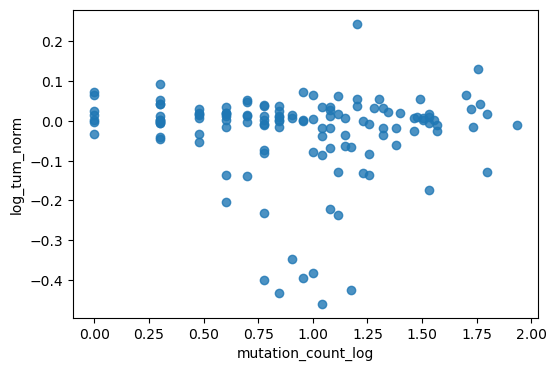

In [26]:
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns
# Gráfico
# ==============================================================================
fig, ax = plt.subplots(1, 1, figsize=(6,4))

# Especificar las columnas correctas para x y y
ax.scatter(x=merge_tumor_normal['mutation_count_log'], y=merge_tumor_normal['log_tum_norm'], alpha=0.8)

ax.set_xlabel('mutation_count_log')
ax.set_ylabel('log_tum_norm')
plt.show()


## Normal

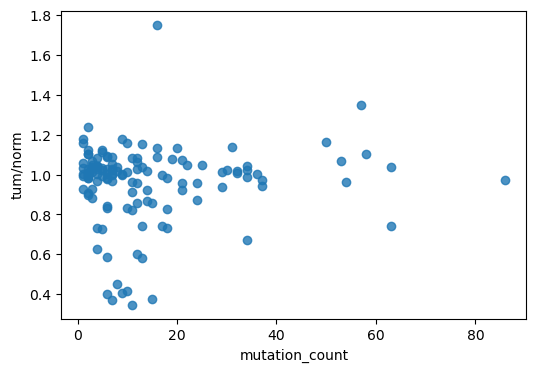

In [27]:
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns
# Gráfico
# ==============================================================================
fig, ax = plt.subplots(1, 1, figsize=(6,4))

# Especificar las columnas correctas para x y y
ax.scatter(x=merge_tumor_normal['mutation_count'], y=merge_tumor_normal['tum/norm'], alpha=0.8)

ax.set_xlabel('mutation_count')
ax.set_ylabel('tum/norm')
plt.show()


KeyError: 'dif_tum_norm'

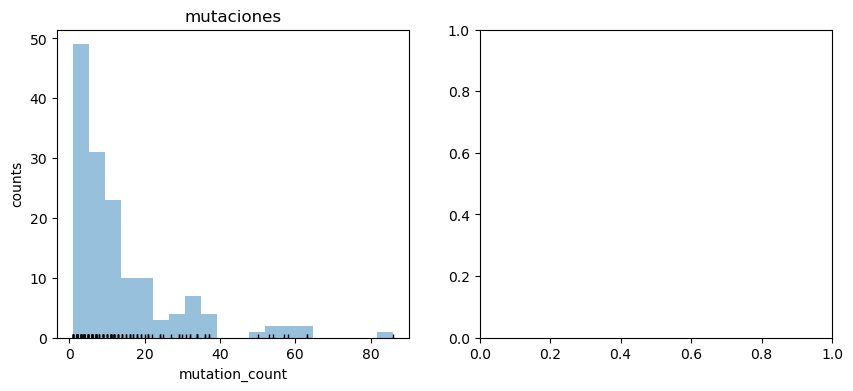

In [28]:
# Gráfico distribución variables
# ==============================================================================
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

axs[0].hist(x=merge_tumor_normal['mutation_count'], bins=20, color="#3182bd", alpha=0.5)
axs[0].plot(merge_tumor_normal['mutation_count'], np.full_like(merge_tumor_normal['mutation_count'], -0.01), '|k', markeredgewidth=1)
axs[0].set_title('mutaciones')
axs[0].set_xlabel('mutation_count')
axs[0].set_ylabel('counts')

axs[1].hist(x=merge_tumor_normal['dif_tum_norm'], bins=20, color="#3182bd", alpha=0.5)
axs[1].plot(merge_tumor_normal['dif_tum_norm'], np.full_like(merge_tumor_normal['dif_tum_norm'], -0.01), '|k', markeredgewidth=1)
axs[1].set_title('expresion')
axs[1].set_xlabel('dif_tum_norm')
axs[1].set_ylabel('counts')


plt.tight_layout();

In [ ]:
# Cálculo de correlación con Pandas
# ==============================================================================
print('Correlación Pearson: ', merge_tumor_normal['mutation_count'].corr(merge_tumor_normal['dif_tum_norm'], method='pearson'))
print('Correlación spearman: ', merge_tumor_normal['mutation_count'].corr(merge_tumor_normal['dif_tum_norm'], method='spearman'))
print('Correlación kendall: ', merge_tumor_normal['mutation_count'].corr(merge_tumor_normal['dif_tum_norm'], method='kendall'))

In [ ]:
import statsmodels.api as sm
import pingouin as pg
from scipy import stats
from scipy.stats import pearsonr

# Cálculo de correlación, significancia e intervalos con pingouin
# ==============================================================================
display(pg.corr(merge_tumor_normal['mutation_count'], merge_tumor_normal['tum/norm'], method='pearson'))
display(pg.corr(merge_tumor_normal['mutation_count'], merge_tumor_normal['tum/norm'], method='spearman'))
display(pg.corr(merge_tumor_normal['mutation_count'], merge_tumor_normal['tum/norm'], method='kendall'))

# 3. Buscar mutaciones por dominios

In [ ]:
df= pd.read_csv('../data/mutaciones/df_frecuencias_mut_STKR.csv')
df

In [ ]:
df_mutaciones = df[['Gen_names', 'tipo_cancer', 'aa_mutation']]

In [ ]:
df_mutaciones.drop_duplicates(subset=['Gen_names', 'tipo_cancer', 'aa_mutation'], inplace = True)
df_mutaciones

In [ ]:
import pandas as pd

# Definir una función para extraer los números de la mutación
def extract_pos(aa_mutation):
    return ''.join(filter(str.isdigit, aa_mutation))

# Aplicar la función a la columna 'aa_mutation' y crear la nueva columna 'mutation_location'
df_mutaciones['pos'] = df_mutaciones['aa_mutation'].apply(extract_pos)

# Función para extraer la letra izquierda y derecha de la mutación
def extract_ref_mut(aa_mutation):
    # Extraer la posición (números)
    mutation_number = ''.join(filter(str.isdigit, aa_mutation))
    
    # Encontrar la posición de los números en la cadena
    number_index = aa_mutation.find(mutation_number)
    
    # Extraer la letra izquierda y derecha
    ref = aa_mutation[number_index - 1] if number_index > 0 else None
    mutation = aa_mutation[number_index + len(mutation_number)] if number_index + len(mutation_number) < len(aa_mutation) else None
    
    return ref, mutation

# Aplicar la función y crear las nuevas columnas 'pos' y 'ref'
df_mutaciones[['ref', 'mutation']] = df_mutaciones['aa_mutation'].apply(lambda x: pd.Series(extract_ref_mut(x)))

# Eliminar duplicados

df_mutaciones.drop_duplicates(['Gen_names', 'aa_mutation',  'tipo_cancer', 'pos', 'ref', 'mutation'], inplace=True)

# Mostrar el DataFrame resultante
df_mutaciones


In [ ]:
# Crea un diccionario para almacenar los DataFrames por gen
df_genes = {}

# Agrupa por 'Gen_names' y crea un DataFrame para cada grupo
for gen, grupo in df_mutaciones.groupby('Gen_names'):
    df_genes[gen] = grupo.reset_index(drop=True)

# Imprimir DataFrames para cada gen
for gen, df_gen in df_genes.items():
    print(f"DataFrame para {gen}:")
    #print(df_gen, "\n")

In [ ]:
df_genes['ACVR1']

## Kinase doamin
 **ACVR1** = 186-496
 


In [ ]:
# Filtra usando loc
df_acvr1_filtrado = df_genes['ACVR1'].loc[df_genes['ACVR1']['pos'] > 185]
